# Assignment 12: Spatial trait variation in California

## BIO597 Spatial Analysis of Biodiversity

Repeat [Lab12](../labs/Lab12-SpatialTraitVariation.ipynb) for California.
How do typical amphibian traits and local trait variation relate to latitude,
climate, and habitat across this larger, environmentally varied state?

Follow the lab's five analyses: community mean traits, functional dispersion,
a trait-shuffling null model, FDis–environment correlations, and a linked
community trait PCA map/biplot.
Use **30 km cells**, pool frogs and salamanders, and give each recorded species
equal weight. You may reuse and adapt code from the lab. Preparation helpers
are supplied so you can concentrate on the ecology.

Submit this notebook with figures, tables, short answers, and a **400–600 word
synthesis**. Include your name and cite the supplied data sources.

*Name:*

## Inputs and environment

Run from `docs/assignments` using the Lab12 environment. The three California
files have the same layout and trait columns as the prepared Maine files:

| Input | Path from this notebook |
| --- | --- |
| Grid, climate, latitude, and habitat fractions | `../data/Lab12/CA_30KM_grid.geojson` |
| Occurrence counts by site and species | `../data/Lab12/CA_Amphib_site_by_species.csv` |
| Species with all five traits | `../data/Lab12/CA_traits.csv` |
| State boundary for map backgrounds | `../data/CA_ShapeFiles/California_State_Boundary.shp` |

The inputs are already prepared from `CA_amphibians.geojson`, `bioclim_CA`,
`CAHabitatMap`, and `AmphiTraits_Final.csv`. **Do not repeat occurrence cleaning,
name matching, gridding, or raster extraction.** Read the
[California preprocessing notes](../data/Lab12/CA_preprocessing.md), including
the species missing traits and the habitat crosswalk.

Records with coordinate uncertainty below 100 m were retained, including repeated
observations. The grid contains cells with more than two species. Counts are
numbers of records, not animal abundances. The California projection is
**EPSG:3310**, not Maine's UTM projection.

In [1]:
from pathlib import Path

import geopandas as gpd
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.decomposition import PCA

CRS = "EPSG:3310"
MIN_COVERAGE = 0.8
N_RANDOM = 1000
SEED = 12
DATA = Path("../data/Lab12")
OUTPUT = Path("outputs/Assignment12/SpatialTraitVariation")
OUTPUT.mkdir(parents=True, exist_ok=True)

## 1. Load the prepared communities and traits

Load the three tables as `sites`, `community`, and `traits`. Use `site_id` as
the index for sites and communities, and `species` for traits, just as in the
lab. Load the boundary as `california` and project it to `CRS`.

Report the number of cells, recorded species, and species with complete traits.
Map recorded richness on the California background. Inspect `n_records` beside
richness and identify species absent from the complete trait table. The
preprocessing notes distinguish an unmatched name from a matched but incomplete
trait row.

Grid cells: 259
Recorded species: 70
Species with complete traits: 30
Species missing traits: 40


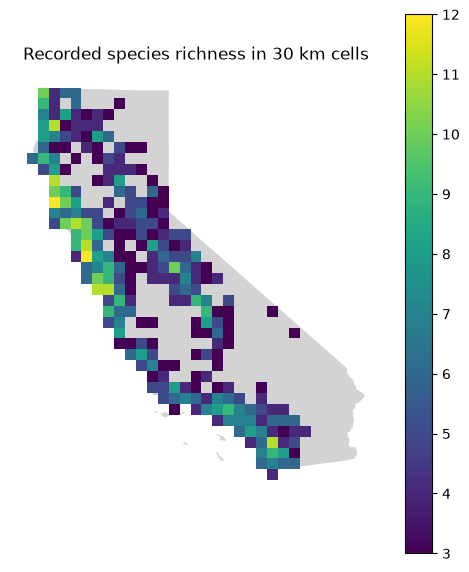

In [2]:
# Load CA_30KM_grid.geojson, CA_Amphib_site_by_species.csv, and CA_traits.csv.
sites = gpd.read_file(DATA / "CA_30KM_grid.geojson")
community = pd.read_csv(DATA / "CA_Amphib_site_by_species.csv", index_col="site_id")
traits = pd.read_csv(DATA / "CA_traits.csv", index_col="species")
# Set the site and species indexes, as in Lab12.
sites = sites.set_index("site_id")
# Load california and project it to CRS.
california = gpd.read_file("../data/CA_ShapeFiles/California_State_Boundary.shp")
california = california.to_crs(CRS)
# Display table sizes, missing-trait species, and a richness map.
print("Grid cells:", len(sites))
print("Recorded species:", len(community.columns))
print("Species with complete traits:", len(traits))
print("Species missing traits:", len(community.columns)-len(traits))
# map
ax = california.plot(color="lightgray", figsize=(6, 7))
sites.plot(ax=ax, column="richness", legend=True, figsize=(6, 7))
ax.set_title("Recorded species richness in 30 km cells")
ax.set_axis_off()
plt.show()

**Interpretation 1:** Where are recorded communities richest? Which sampling
gaps or differences in record totals might affect that pattern? Why must species
without complete traits still contribute to richness? Distinguish a species
absent from the trait table from a species absent from a cell.

Before looking at trait correlations, propose one directional hypothesis about
a trait and latitude, climate, or habitat, with a biological explanation.

*Your answer:* Recorded communities are richest along the northern and southern coast, plus in the central Sierra Nevada mountains. There are obvious sampling gaps in the southern desert and central plains, which are bordered by apparent low-richness cells, but it is likely that these communities with lower richness actually are under-sampled compared to coastal and mountain communities. Species without complete traits still must contribute to richness because they are part of the communities, they just don't have complete information collected. Removing these species would substantially reduce richness estimates, possibly unevenly, leading to artificial differences in richness among communities.

## 2. Put species in a shared trait space

Use all five supplied traits. Log-transform them, standardize the columns,
and fit a two-component **species PCA**. Save `trait_space`, `trait_pca`,
`species_scores`, and `loadings`, following the lab. Plot species in PCA space,
label them, and display the loadings and variance explained.

Traits describe typical species values, not measurements of animals at each
observation. Frogs and salamanders remain together throughout this assignment.

In [3]:
TRAIT_COLUMNS = list(traits.columns)
TRAIT_LABELS = {
    "MaxBody": "Maximum adult length (mm)",
    "MinAgeMat": "Minimum maturity age (years)",
    "MaxClutch": "Maximum clutch size",
    "MinSizeMat": "Minimum size at maturity (mm)",
    "MinClutch": "Minimum clutch size",
}
trait_lookup = traits

,PC1,PC2
MaxBody,-0.364826,0.558965
MinAgeMat,-0.436368,0.017596
MaxClutch,0.539965,0.382823
MinSizeMat,-0.330057,0.618403
MinClutch,0.525344,0.397836


,MaxBody,MinAgeMat,MaxClutch,MinSizeMat,MinClutch
species,,,,,
Ambystoma californiense,184.0,2.0,1340.0,75.0,413.0
Ambystoma gracile,219.0,2.0,270.0,70.0,30.0
Ambystoma macrodactylum,248.0,1.0,411.0,53.0,90.0
Anaxyrus boreas,125.0,3.0,16500.0,56.0,3239.0
Anaxyrus californicus,81.0,2.0,10368.0,51.0,2013.0
Anaxyrus canorus,69.0,3.0,5000.0,48.0,1500.0
Anaxyrus cognatus,114.0,2.0,45054.0,47.0,1342.0
Anaxyrus microscaphus,81.0,2.0,4500.0,53.0,3153.0
Aneides ferreus,133.0,2.0,18.0,75.0,6.0


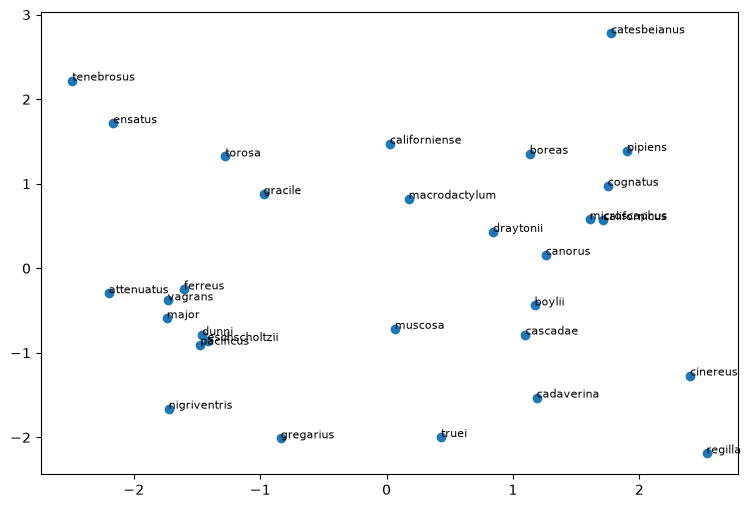

In [4]:
# Log10-transform and standardize traits, then create trait_space.
logged = np.log10(traits)
scaler = StandardScaler()
standardized = scaler.fit_transform(logged)
trait_space = pd.DataFrame(standardized, index=traits.index, columns=TRAIT_COLUMNS)
# Fit trait_pca and make species_scores and loadings.
trait_pca = PCA(n_components=2)
scores = trait_pca.fit_transform(standardized)
species_scores = pd.DataFrame(scores, index=traits.index, columns=["PC1", "PC2"])
# Plot the species and report the variance explained by PC1 and PC2.
fig, ax = plt.subplots(figsize=(9, 6))
ax.scatter(species_scores["PC1"], species_scores["PC2"])
for name, point in species_scores.iterrows():
    epithet = name.split()[1]
    ax.text(point["PC1"], point["PC2"], epithet, fontsize=8)

loadings = pd.DataFrame(trait_pca.components_.T, index=TRAIT_COLUMNS, columns=["PC1", "PC2"])
display(loadings)
display(traits)

In [5]:
trait_space.head()

,MaxBody,MinAgeMat,MaxClutch,MinSizeMat,MinClutch
species,,,,,
Ambystoma californiense,0.845317,-0.197461,0.488992,0.956276,0.571074
Ambystoma gracile,1.189450,-0.197461,-0.137080,0.789968,-0.553495
Ambystoma macrodactylum,1.435208,-1.757150,0.027125,0.119354,-0.082348
Anaxyrus boreas,0.081261,0.714898,1.470184,0.252077,1.454335
Anaxyrus californicus,-0.776157,-0.197461,1.288601,0.026631,1.250354


**Interpretation 2:** What biological combinations distinguish the two axes?
Choose two nearby species and two contrasting species, referring to their
original trait values. Why log-transform and standardize? Why should functional
dispersion use all five traits even when the figure displays two PCs?

*Your answer:* The two axes are distinguished by species' maximum clutch size and minimum size at maturity. Two nearby species are Plethodon dunni and Ensatina eschscholtzii (MaxClutch = 18.0 vs. 25.0, MinSizeMat = 50.0 vs. 48.0). These differences are all < 10 units away from each other, and if they were compared at the original scale, they would be indistinguishable from each other due to both of their differences from farther away species such as Lithobates catesbeianus (which, for example, has a maximum clutch size of 25,000).  Functional dispersion should use all five traits because they all contribute to a species' ecological niche, and the PCA loadings indicate that there is trait variation despite the fact that there are only two PCs displayed in this plot.

## 3. Map typical community traits

Use the supplied helper from Lab12. Each species present receives one vote;
repeated records do not increase its weight. The helper returns a geometric
mean and the proportion of recorded species with trait information. Means below
80% coverage remain missing.

Build `trait_maps` for all five traits. Map maximum body length, maturity age,
and maximum clutch size, using `california` as the background. Inspect coverage
as well as the trait means; do not fill missing means with zero.

In [6]:
def summarize_trait(sites, community, column):
    result = sites.copy()
    means = []
    coverages = []
    for site_id, row in community.iterrows():
        # Get only the species that occur in this community
        names = row[row > 0].index
        # reindex the trait lookup table to only have those species present
        species_traits = trait_lookup.reindex(names)
        values = species_traits[column]
        values = values.dropna()
        # calculate the fraction of species that have trait info
        coverage = len(values) / len(names)
        coverages.append(coverage)
        if coverage >= MIN_COVERAGE:
            log_values = np.log10(values)
            means.append(10 ** log_values.mean())
        else:
            means.append(np.nan)
    result["trait_mean"] = means
    result["trait_coverage"] = coverages
    return result

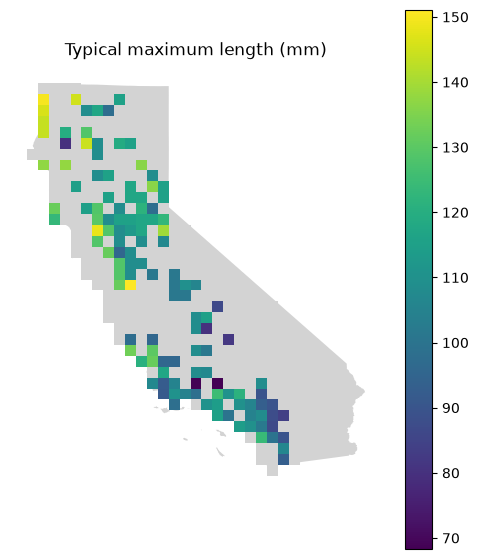

Sites missing traits:  132
Total sites:  259


In [7]:
# Build trait_maps by calling summarize_trait for each trait.
trait_maps = {}
for column in TRAIT_COLUMNS:
    trait_maps[column] = summarize_trait(sites, community, column)
# Map MaxBody, MinAgeMat, and MaxClutch with appropriate labels.
ax = california.plot(color="lightgray", figsize=(6, 7))
sites.plot(ax=ax, color="lightgray", figsize=(6, 7))
trait_maps["MaxBody"].plot(ax=ax, column="trait_mean", legend=True)
ax.set_title("Typical maximum length (mm)")
ax.set_axis_off()
plt.show()
# Examine how many cells retain valid trait means and where coverage is low.
print("Sites missing traits: ", trait_maps['MaxBody']["trait_mean"].isna().sum())
print("Total sites: ", len(sites))

**Interpretation 3:** Where do typical community traits differ? Could missing
traits or differences in sampling help explain those patterns? Describe what
"typical maximum body length" means without treating it as mean animal size.
Which areas are excluded by the coverage requirement?

*Your answer:* Traits seem to differ in the northern part of the state, particularly near Redwood National Park, and in the north-central part of the state near Sacramento. This map shows "typical maximum body length", which is the value that is considered typical for the species, but it is not a mean of the records displayed. There are several areas that have been excluded (only 132 of the original 259 sites are displayed in this map), but most importantly the central coast (Bay Area) is now excluded, whereas we saw in the earlier map that there were several records from that area and high richness estimates.

### Compare typical traits with the predictors

The prepared grid includes midpoint latitude, all 19 BIO variables, and habitat
area fractions. These are **cell means and area fractions**, rather than SDs or
the habitat proportions of occurrence records. Habitat fractions sum to one over
classified pixels in the California portion of each cell, including mapped water.

California's original map legend differs from Maine's. The first six broad groups
are analogous to the lab; `habitat_introduced` and `habitat_disturbed` retain two
additional mapped categories. "Other natural" includes shrubland, grassland,
desert, alpine and rock vegetation. Exact habitat comparisons between states
require care because the source maps differ.

Calculate descriptive **Spearman correlations** between typical maximum length
and every predictor. Make six example scatterplots using `PLOT_PREDICTORS`.
You may substitute other predictors if you explain the choice.

In [8]:
CLIMATE_COLUMNS = {
    "bio_1": "Annual mean temperature (°C)",
    "bio_2": "Mean diurnal temperature range (°C)",
    "bio_3": "Isothermality (%)",
    "bio_4": "Temperature seasonality (SD × 100)",
    "bio_5": "Maximum temperature, warmest month (°C)",
    "bio_6": "Minimum temperature, coldest month (°C)",
    "bio_7": "Annual temperature range (°C)",
    "bio_8": "Mean temperature, wettest quarter (°C)",
    "bio_9": "Mean temperature, driest quarter (°C)",
    "bio_10": "Mean temperature, warmest quarter (°C)",
    "bio_11": "Mean temperature, coldest quarter (°C)",
    "bio_12": "Annual precipitation (mm)",
    "bio_13": "Precipitation, wettest month (mm)",
    "bio_14": "Precipitation, driest month (mm)",
    "bio_15": "Precipitation seasonality (CV)",
    "bio_16": "Precipitation, wettest quarter (mm)",
    "bio_17": "Precipitation, driest quarter (mm)",
    "bio_18": "Precipitation, warmest quarter (mm)",
    "bio_19": "Precipitation, coldest quarter (mm)",
}

HABITAT_COLUMNS = {
    "habitat_agriculture": "Agriculture fraction",
    "habitat_developed": "Developed fraction",
    "habitat_open_water": "Open water fraction",
    "habitat_other_natural": "Other natural habitat fraction",
    "habitat_upland_forest": "Upland forest fraction",
    "habitat_wetland": "Wetland/aquatic vegetation fraction",
    "habitat_introduced": "Introduced vegetation fraction",
    "habitat_disturbed": "Recently disturbed fraction",
}
PREDICTORS = {"latitude": "Midpoint latitude (°N)"}
PREDICTORS.update(CLIMATE_COLUMNS)
PREDICTORS.update(HABITAT_COLUMNS)


PLOT_PREDICTORS = ["latitude", "bio_19", "bio_13", "bio_16",
                   "habitat_upland_forest", "habitat_developed"]

{'latitude': np.float64(0.51),
 'bio_1': np.float64(-0.28),
 'bio_2': np.float64(-0.31),
 'bio_3': np.float64(0.02),
 'bio_4': np.float64(-0.14),
 'bio_5': np.float64(-0.31),
 'bio_6': np.float64(0.02),
 'bio_7': np.float64(-0.23),
 'bio_8': np.float64(-0.26),
 'bio_9': np.float64(-0.26),
 'bio_10': np.float64(-0.33),
 'bio_11': np.float64(-0.2),
 'bio_12': np.float64(0.5),
 'bio_13': np.float64(0.54),
 'bio_14': np.float64(0.25),
 'bio_15': np.float64(0.0),
 'bio_16': np.float64(0.51),
 'bio_17': np.float64(0.24),
 'bio_18': np.float64(0.22),
 'bio_19': np.float64(0.53),
 'habitat_agriculture': np.float64(-0.11),
 'habitat_developed': np.float64(-0.06),
 'habitat_open_water': np.float64(0.19),
 'habitat_other_natural': np.float64(-0.37),
 'habitat_upland_forest': np.float64(0.33),
 'habitat_wetland': np.float64(0.15),
 'habitat_introduced': np.float64(0.06),
 'habitat_disturbed': np.float64(0.23)}

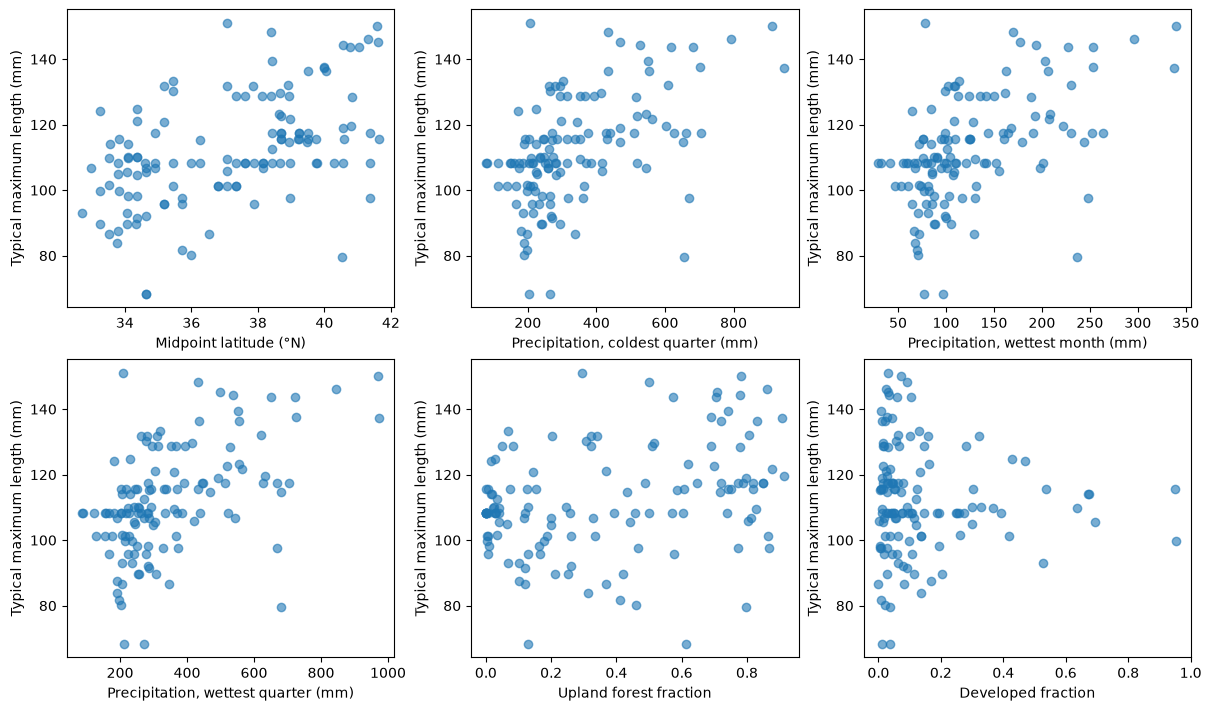

In [9]:
# Compare trait_maps["MaxBody"] with all predictors using Spearman correlation.
table = trait_maps["MaxBody"]
corrs = {}
for predictor in PREDICTORS:
    data = table.dropna(subset=["trait_mean", predictor])
    rho = data[predictor].corr(data["trait_mean"], method="spearman")
    corrs[predictor] = round(rho, 2)
display(corrs)

# Plot six example relationships with labels from PREDICTORS.
fig, axes = plt.subplots(2, 3, figsize=(12, 7), layout="constrained")
for ax, predictor in zip(axes.flat, PLOT_PREDICTORS):
    data = table.dropna(subset=["trait_mean", predictor])
    ax.scatter(data[predictor], data["trait_mean"], alpha=0.6)
    ax.set(xlabel=PREDICTORS[predictor], ylabel="Typical maximum length (mm)")
plt.show()

**Interpretation 4:** Does the pattern support your initial hypothesis?
Compare a geographic, a climatic, and a habitat relationship. Why would a strong
correlation alone fail to identify an independent cause? Explain how habitat
fractions constrain one another.

*Your answer:* I replaced the original bio predictors with those that had correlation coefficients > 0.5. Looking at the plots, we see that maximum body length increases with latitude (this agrees with Bergman's rule). We also see body length increase with precipitation, but this could be the result of high correlation between latitude and precipitation. Looking at the habitat fractions, it's difficult to disentangle the effect of each alone. For example, "developed fraction" does not provided information on what habitat makes up the other fractions of the site--it could be upland forest, wetland, open water, etc. Similarly, "upland forest fraction" may also be made up of developed area or of wetlands, or anything in between. 

## 4. Richness versus functional dispersion

The community matrix includes species without complete traits. **Do not use
`trait_space.loc[names]` on the full species list.** The supplied code below
selects species with complete traits and cells with at least three of those
species and at least 80% coverage. Use `functional_sites` and
`functional_presence` for all FDis calculations and the null model.

Use the lab's dispersion function to calculate FDis for each retained cell,
using all five standardized log traits. Map `trait_richness` and FDis, then plot
their relationship. Also inspect how trait richness differs from total recorded
richness. The cell mean trait maps and FDis summarize different properties.

In [10]:
# Select complete-trait species and keep matching grid cells.
known_presence = community[trait_space.index] > 0
functional_sites = sites.copy()
functional_sites["trait_richness"] = known_presence.sum(axis=1)
functional_sites["trait_coverage"] = functional_sites["trait_richness"] / sites["richness"]
functional_sites = functional_sites[functional_sites["trait_coverage"] >= MIN_COVERAGE]
functional_sites = functional_sites[functional_sites["trait_richness"] >= 3].copy()
functional_presence = known_presence.loc[functional_sites.index]
print("Cells retained for functional analyses:", len(functional_sites))


def dispersion(values):
    centroid = values.mean(axis=0)
    squared_differences = (values - centroid) ** 2
    distances = np.sqrt(squared_differences.sum(axis=1))
    return distances.mean()

Cells retained for functional analyses: 127


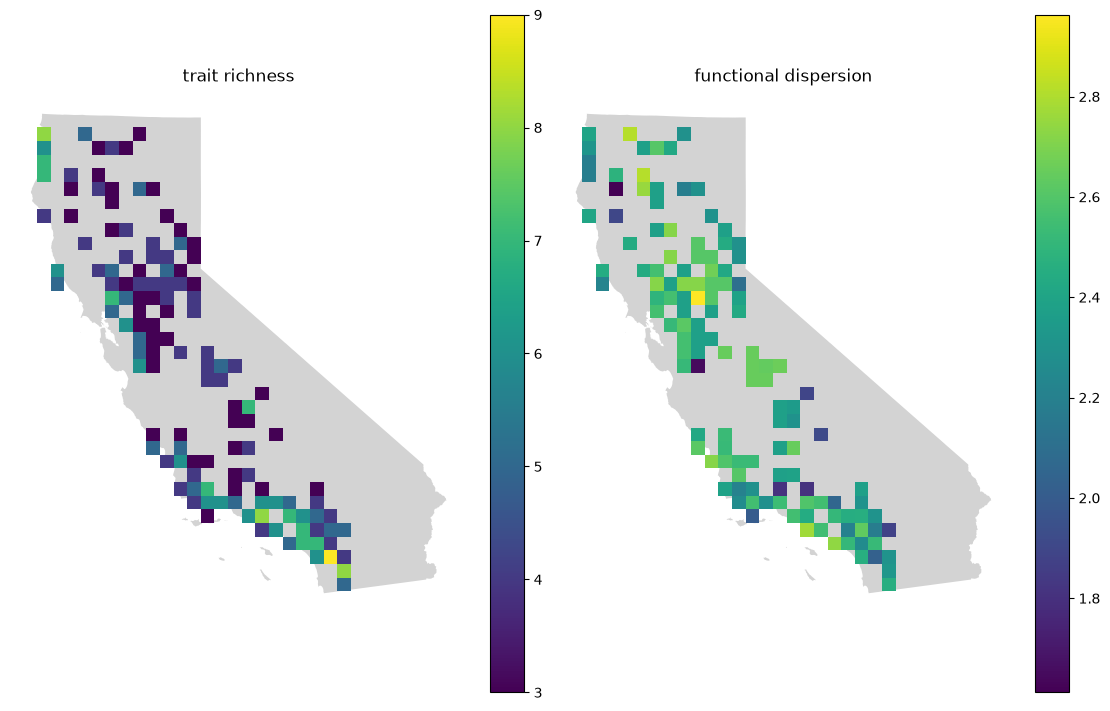

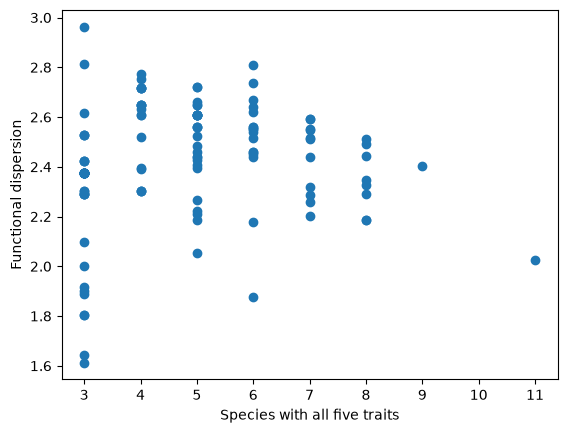

In [11]:
# For each row of functional_presence, select the species present.
values = []
for site_id, row in functional_presence.iterrows():
    names = row[row > 0].index
    species_traits = trait_space.loc[names]    
# Look up their standardized traits and calculate dispersion.
    values.append(dispersion(species_traits.to_numpy()))
# Store the results in functional_sites["functional_dispersion"].
functional_sites["functional_dispersion"] = values
# Map trait_richness and functional_dispersion, and plot their relationship.
fig, axes = plt.subplots(1, 2, figsize=(11, 7), layout="constrained")
for ax, column in zip(axes, ["trait_richness", "functional_dispersion"]):
    california.plot(ax=ax, color="lightgray", figsize=(6, 7))
    functional_sites.plot(ax=ax, color="lightgray")
    functional_sites.plot(ax=ax, column=column, legend=True)
    ax.set_title(column.replace("_", " "))
    ax.set_axis_off()
plt.show()

plt.scatter(functional_sites["richness"], functional_sites["functional_dispersion"])
plt.xlabel("Species with all five traits")
plt.ylabel("Functional dispersion")
plt.show()

### Hold richness fixed

Among retained cells with **four trait-covered species**, select the lowest and
highest FDis. Draw their species on the species PCA with the regional species
pool in gray and the local centroid marked. Print both species lists and FDis
values. Use `trait_richness`, not total richness, to hold the number of analyzed
species fixed.

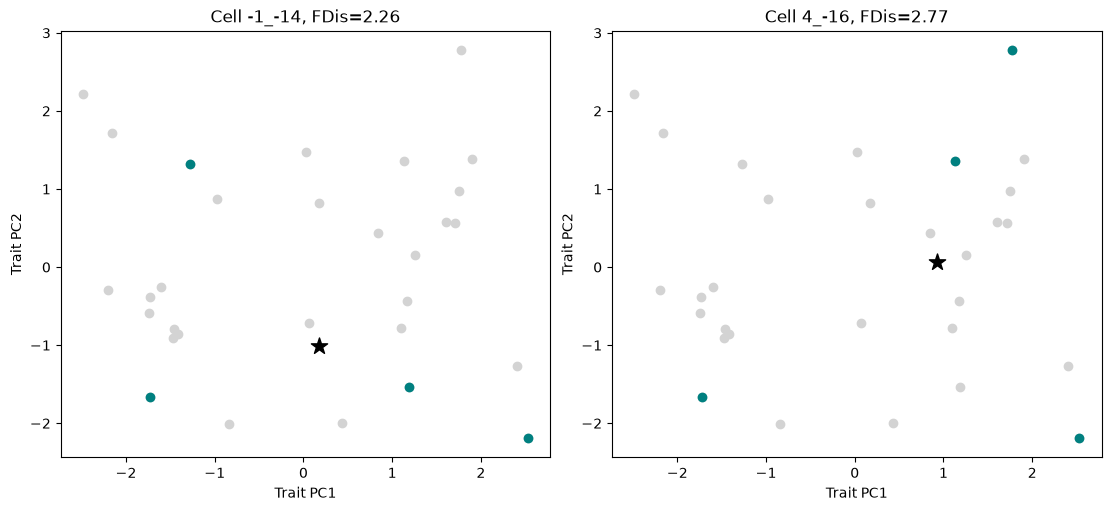

Only site -1_-14: ['Pseudacris cadaverina', 'Taricha torosa']
Only site 4_-16: ['Anaxyrus boreas', 'Lithobates catesbeianus']
Shared: ['Batrachoseps nigriventris', 'Pseudacris regilla']


,MaxBody,MinAgeMat,MaxClutch,MinSizeMat,MinClutch
species,,,,,
Pseudacris cadaverina,51.0,2.0,265.0,32.0,265.0
Taricha torosa,197.0,3.0,160.0,90.0,130.0
Anaxyrus boreas,125.0,3.0,16500.0,56.0,3239.0
Lithobates catesbeianus,204.0,1.0,25500.0,90.0,8000.0
Batrachoseps nigriventris,140.0,3.5,9.0,31.0,4.0
Pseudacris regilla,50.0,1.0,807.0,19.0,265.0


In [12]:
# Find low and high FDis cells with trait_richness == 4.
candidates = functional_sites[functional_sites["trait_richness"] == 4]
lowest = candidates["functional_dispersion"].idxmin()
highest = candidates["functional_dispersion"].idxmax()
# Plot each local species set and centroid on the species PCA.
fig, axes = plt.subplots(1, 2, figsize=(11, 5), layout="constrained")
for ax, site_id in zip(axes, [lowest, highest]):
    present = functional_presence.loc[site_id]
    names = present[present > 0].index
    selected = species_scores.loc[names]
    ax.scatter(species_scores["PC1"], species_scores["PC2"], color="lightgray")
    ax.scatter(selected["PC1"], selected["PC2"], color="teal")
    ax.scatter(selected["PC1"].mean(), selected["PC2"].mean(), marker="*", color="black", s=150)
    fdis = functional_sites.loc[site_id, "functional_dispersion"]
    ax.set(title=f"Cell {site_id}, FDis={fdis:.2f}", xlabel="Trait PC1", ylabel="Trait PC2")
plt.show()
# Print the cell IDs, species lists, and FDis values.

site1 = functional_presence.loc["-1_-14"]
site2 = functional_presence.loc["4_-16"]
print("Only site -1_-14:", site1[site1 & ~site2].index.tolist())
print("Only site 4_-16:", site2[site2 & ~site1].index.tolist())
print("Shared:", site1[site1 & site2].index.tolist())

# view traits for these species
display(traits.loc[['Pseudacris cadaverina', 'Taricha torosa', 'Anaxyrus boreas', 'Lithobates catesbeianus', 'Batrachoseps nigriventris', 'Pseudacris regilla']])

**Interpretation 5:** Which species and traits create the contrast? Can two
equally rich communities have different functional diversity? Explain why a PCA
picture can miss differences measured by the full five-dimensional FDis.
Would your conclusions change if the excluded species had very unusual traits?

*Your answer:* The species that are different between these two sites are Pseudacris cadaverina and Taricha torosa (only at site -1_-14) and Anaxyrus boreas and Lithobates catesbeianus (only at site 4_-16). The major trait differences between these species are MaxClutch and MinClutch: these two values are orders of magnitude higher for the species unique to site 4_-16 compared to site -1_-14. The 2D PCA does not show these differences because it only shows PC1 and 2 (MaxClutch and MinSizeMat) and does not consider MinClutch. If the excluded species had unsual traits, then the conclusions would certainly change because these newly considered species would add variation and potentially change the importance of traits.

## 5. Compare dispersion with a null model

Use **1,000 shuffles** and seed 12, matching the current lab. Each shuffle
reassigns whole five-trait profiles among the complete-trait California species
while keeping each cell's species list fixed. The helper is provided below.

Call it with `functional_presence`, not raw record counts or a different set of
cells. Save the result as `null_draws`. Copy `functional_sites` to `null_sites`,
calculate the null mean and sample SD for each cell, and calculate:

`ses_fdis = (observed FDis - null mean) / null SD`

Leave SES missing when the null SD is zero or nearly zero, as in the lab.
Map SES with a common scale of −3 to +3. Plot a null histogram for one cell and
mark its observed FDis. These effect sizes are not, by themselves, p-values.

In [13]:
def null_dispersion(presence, trait_space, n_random):
    # Match the species order, then turn occurrence counts into presence/absence.
    presence = presence[trait_space.index]
    presence = presence > 0
    values = trait_space.to_numpy()
    rng = np.random.default_rng(SEED)

    # Store one dispersion value per randomization and grid cell.
    simulated = np.zeros((n_random, len(presence)))
    for draw in range(n_random):
        # Reassign whole trait profiles among species; keep all five traits together.
        shuffled = rng.permutation(values)
        for site_number, present in enumerate(presence.to_numpy()):
            # Keep the cell's species list fixed and calculate its shuffled dispersion.
            simulated[draw, site_number] = dispersion(shuffled[present])
    return simulated

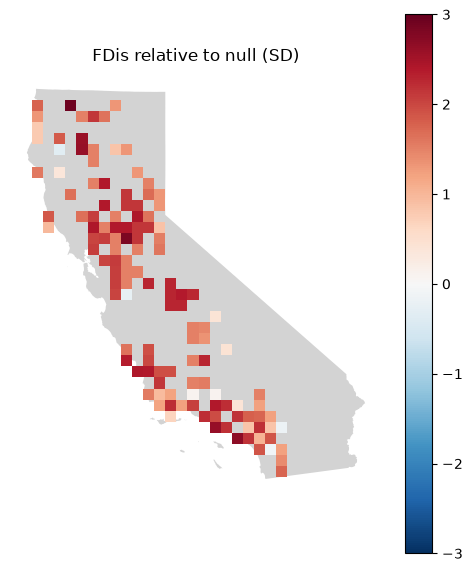

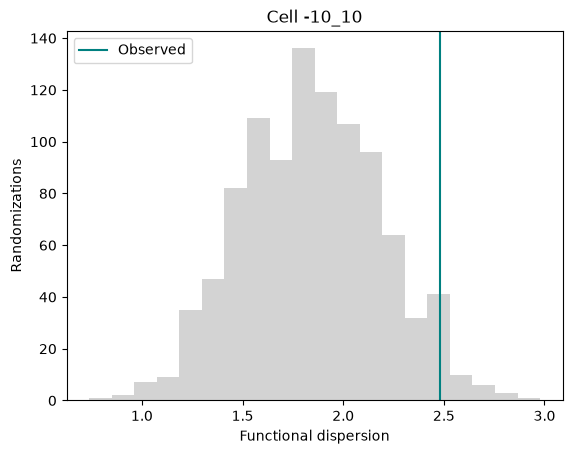

In [14]:
# Generate null_draws from functional_presence, trait_space, and N_RANDOM.
null_draws = null_dispersion(functional_presence, trait_space, N_RANDOM)
# Calculate null_mean, null_sd, and ses_fdis in null_sites.
null_sites = functional_sites.copy()
null_sites["null_mean"] = null_draws.mean(axis=0)
null_sites["null_sd"] = null_draws.std(axis=0, ddof=1)
# Map SES and compare one observed cell with its null histogram.
null_sites.loc[null_sites["null_sd"] < 1e-10, "null_sd"] = np.nan
difference = null_sites["functional_dispersion"] - null_sites["null_mean"]
null_sites["ses_fdis"] = difference / null_sites["null_sd"]

ax = california.plot(color="lightgray", figsize=(6, 7))
functional_sites.plot(ax=ax, color="lightgray", figsize=(6, 7))
null_sites.plot(ax=ax, column="ses_fdis", cmap="RdBu_r", vmin=-3, vmax=3, legend=True)
ax.set_title("FDis relative to null (SD)")
ax.set_axis_off()
plt.show()

# Look at the randomization distribution for one cell.
examples = null_sites.dropna(subset=["ses_fdis"])
site_id = examples.index[0]
position = null_sites.index.get_loc(site_id)
plt.hist(null_draws[:, position], bins=20, color="lightgray")
observed = null_sites.loc[site_id, "functional_dispersion"]
plt.axvline(observed, color="teal", label="Observed")
plt.title(f"Cell {site_id}")
plt.xlabel("Functional dispersion")
plt.ylabel("Randomizations")
plt.legend()
plt.show()

**Interpretation 6:** Which communities are more clustered or spread out
than expected from this regional pool? What does the null model keep fixed?
Why shuffle all traits together? Explain why clustering does not establish
environmental filtering and why the choice of species pool matters.

*Your answer:* Almost all communities have higher FDis (more spread out) than expected by the null model. There are a few communities scattered on the map with near-0 relative FDis, but there isn't an obvious spatial pattern. It makes sense to consider all traits together because the PCA should a good amount of variation in all traits, and the specific traits affected by environmental filtering will depend on the environment. Clustering alone does not establish environmental filtering, though, because there could be other reasons behind clustering such as detection (perhaps species with certain traits are easier to detect and more likely to be recorded).

## 6. Evaluate correlations between FDis and environmental predictors

Repeat **Step 4 of Lab12** using the California communities. Calculate
**Pearson correlations** between observed `functional_dispersion` and every
predictor. Use `null_sites`, which already contains the observed FDis and
predictors for the retained cells. Omit missing values for each comparison.

Display the correlations and make the same six scatterplots as the lab using
`PLOT_PREDICTORS`: latitude, annual mean temperature, minimum temperature of
the coldest month, mean temperature of the warmest quarter, upland forest
fraction, and developed fraction. Label the vertical axis **Functional dispersion**.

These plots describe how much traits vary within communities. Use observed
FDis here; the SES map in Section 5 asks whether that spread differs from the
regional null expectation. The correlations are descriptive, and nearby cells
share species and environmental conditions.

Pearson correlations


{'latitude': np.float64(0.1),
 'bio_1': np.float64(0.27),
 'bio_2': np.float64(0.01),
 'bio_3': np.float64(-0.02),
 'bio_4': np.float64(0.01),
 'bio_5': np.float64(0.22),
 'bio_6': np.float64(0.22),
 'bio_7': np.float64(0.01),
 'bio_8': np.float64(0.23),
 'bio_9': np.float64(0.3),
 'bio_10': np.float64(0.24),
 'bio_11': np.float64(0.21),
 'bio_12': np.float64(-0.05),
 'bio_13': np.float64(-0.01),
 'bio_14': np.float64(-0.17),
 'bio_15': np.float64(0.2),
 'bio_16': np.float64(-0.03),
 'bio_17': np.float64(-0.19),
 'bio_18': np.float64(-0.26),
 'bio_19': np.float64(-0.03),
 'habitat_agriculture': np.float64(0.14),
 'habitat_developed': np.float64(0.24),
 'habitat_open_water': np.float64(-0.01),
 'habitat_other_natural': np.float64(-0.2),
 'habitat_upland_forest': np.float64(-0.07),
 'habitat_wetland': np.float64(0.1),
 'habitat_introduced': np.float64(-0.18),
 'habitat_disturbed': np.float64(-0.12)}

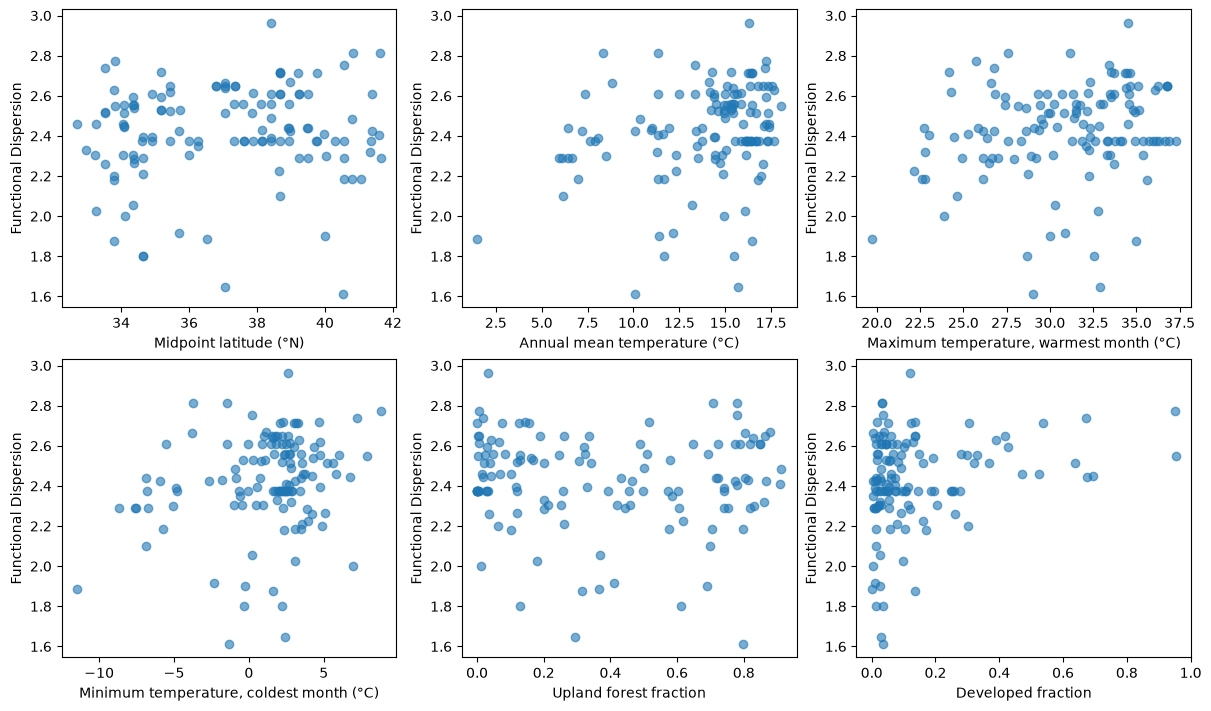

In [15]:
# Calculate Pearson correlations between functional_dispersion and all PREDICTORS.
# create new predictors based on correlations
PLOT_PREDICTORS = ["latitude", "bio_1", "bio_5", "bio_6",
                   "habitat_upland_forest", "habitat_developed"]

Fdis_corrs = {}
for predictor in PREDICTORS:
    data = null_sites.dropna(subset=["functional_dispersion", predictor])
    r = data[predictor].corr(data["functional_dispersion"], method="pearson")
    Fdis_corrs[predictor] = round(r, 2)
# Drop missing values for each comparison and display the correlations.
print("Pearson correlations")
display(Fdis_corrs)
# Make six FDis scatterplots using PLOT_PREDICTORS, as in Lab12 Step 4.
fig, axes = plt.subplots(2, 3, figsize=(12, 7), layout="constrained")
for ax, predictor in zip(axes.flat, PLOT_PREDICTORS):
    data = null_sites.dropna(subset=["functional_dispersion", predictor])
    ax.scatter(data[predictor], data["functional_dispersion"], alpha=0.6)
    ax.set(xlabel=PREDICTORS[predictor], ylabel="Functional Dispersion")
plt.show()

**Interpretation 7:** Which predictors have the strongest associations with
trait dispersion? Do these resemble the relationships with typical maximum
length? Distinguish a community's mean traits, its observed trait spread, and
its departure from the regional null expectation. Propose one biological
explanation for the strongest pattern and one alternative involving sampling
or species availability.

*Your answer:* bio_1, bio_5, and bio_6 have the strongest correlations with trait dispersion. These are different from the highest correlations with the individual trait of maximum body length, and the correlations are less strong. A community's mean traits are different from the observed trait spread for a number of reasons, one of which is that the true mean trait may not be captured in the observed traits if a representative pool isn't sampled. Another reason is that mean trait does not reflect variation within the community, whereas the trait spread does. A trait mean can be the same across sample pools while the trait spread differs greatly. A community's departure from the null expectation may also be the result of factors beyond trait mean and spread depending on whether the species richness and diversity are accurately reflected in the sample pool. Regarding the strongest pattern, which is that Functional dispersion increases with annual mean temperature, this may be the result of high temperatures leading to high biological productivity, which creates ample and diverse habitats to host species with diverse traits, or could reflect higher sampling effort in areas with higher temperatures.

## 7. Put community trait combinations on the map

Repeat the lab's final synthesis using the retained functional cells:

1. Assemble their five geometric mean traits from `trait_maps`, take log10,
   standardize, and fit a new **community PCA**. One row is now a grid cell.
2. Rank every predictor by its average squared Pearson correlation with the
   five log community mean traits. Select the leading climate variable and
   leading habitat fraction. This ranking is descriptive, not a significance test.
3. Color cells using their first two PC scores, as in the lab. Use identical
   colors for each cell on the California map and in the PCA scatterplot.
4. Add arrows for **latitude, the leading climate variable, and the leading
   habitat fraction**, using their correlations with the displayed PC axes.

Keep names such as `community_traits`, `community_pca`, `community_scores`,
`community_loadings`, `predictor_ranking`, and `map_sites` from the lab. Use
`sites` for the gray background and only the retained cells for the colored map.
Report the variance explained and show the trait loadings and predictor ranking.

In [16]:
from sklearn.preprocessing import MinMaxScaler
# Build community_traits for functional_sites.index from the five trait_maps.
community_traits = pd.DataFrame(index=functional_sites.index)

# Log10-transform, standardize, and calculate community_scores and loadings.
for trait in TRAIT_COLUMNS:
    community_traits[trait] = np.log10(trait_maps[trait]["trait_mean"])
community_traits = community_traits.dropna()
scaler = StandardScaler()
scaled_traits = scaler.fit_transform(community_traits)
community_pca = PCA(n_components=2)
scores = community_pca.fit_transform(scaled_traits)
community_scores = pd.DataFrame(scores, index=community_traits.index, columns=["PC1", "PC2"])
community_loadings = pd.DataFrame(community_pca.components_.T,
                                 index=TRAIT_COLUMNS, columns=["PC1", "PC2"])

# Rank PREDICTORS using all five log community mean traits.
predictor_strength = {}
for predictor in PREDICTORS:
    squared_correlations = []
    for trait in TRAIT_COLUMNS:
        r = functional_sites[predictor].corr(community_traits[trait])
        squared_correlations.append(r ** 2)
    predictor_strength[predictor] = np.mean(squared_correlations)

predictor_ranking = pd.Series(predictor_strength, name="mean_r_squared")
predictor_ranking = predictor_ranking.sort_values(ascending=False)
best_climate = predictor_ranking.loc[list(CLIMATE_COLUMNS)].idxmax()
best_habitat = predictor_ranking.loc[list(HABITAT_COLUMNS)].idxmax()

# Select latitude, the leading climate variable, and the leading habitat fraction.
FOCUS = ["latitude", best_climate, best_habitat]

Midpoint latitude (°N) Midpoint latitude (°N)
BIO7 Annual temperature range (°C)
Agriculture fraction Agriculture fraction


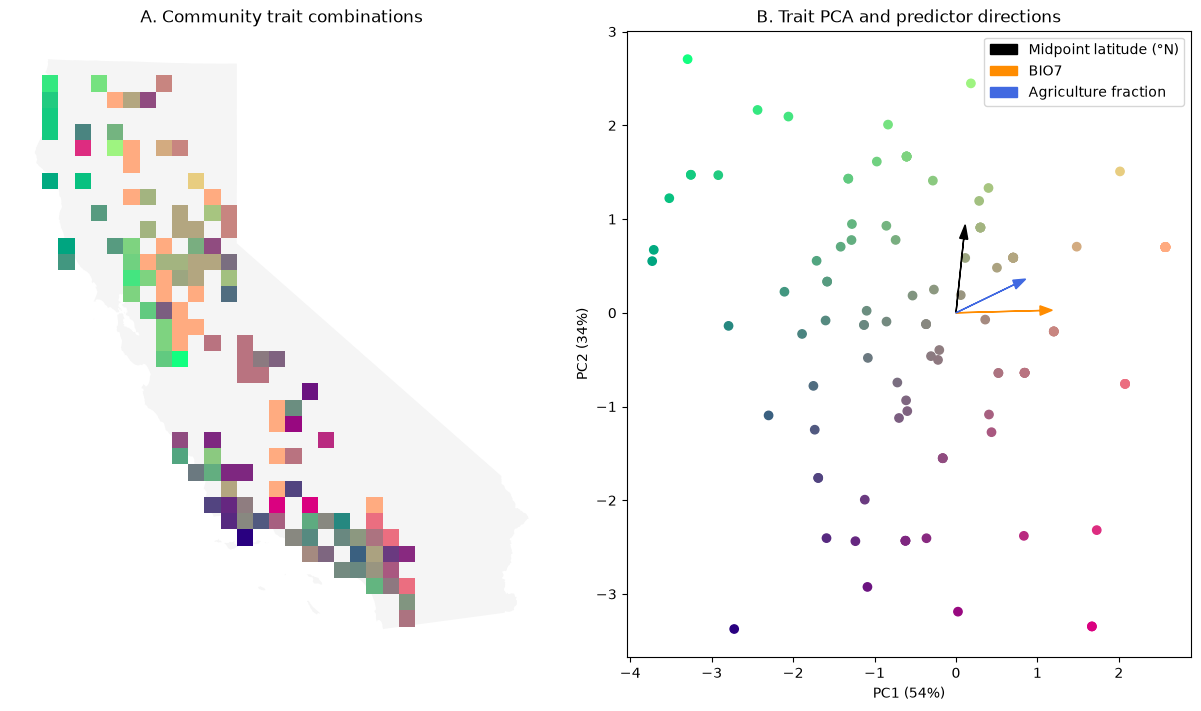

In [17]:
# Assign PCA-based colors, following Lab12.
color_scores = MinMaxScaler().fit_transform(community_scores)
community_colors = np.zeros((len(community_scores), 3))
community_colors[:, :2] = color_scores
community_colors[:, 2] = 0.5
community_colors = np.clip(community_colors, 0, 1) # clip random value of 1.0000002 to 1

# Make the linked California grid map and community PCA scatterplot.
map_sites = functional_sites.loc[community_scores.index].copy()
map_sites[["PC1", "PC2"]] = community_scores

fig, axes = plt.subplots(1, 2, figsize=(12, 7), layout="constrained")

california.plot(ax=axes[0], color="whitesmoke")
functional_sites.plot(ax=axes[0], color="lightgray")
map_sites.plot(ax=axes[0], color=community_colors)
axes[0].set_title("A. Community trait combinations")
axes[0].set_axis_off()

ax = axes[1]
ax.scatter(community_scores["PC1"], community_scores["PC2"], c=community_colors)
for predictor, color in zip(FOCUS, ["black", "darkorange", "royalblue"]):
    # Scale both correlations equally so the arrows are easy to see.
    x = 2 * functional_sites[predictor].corr(community_scores["PC1"])
    y = 2 * functional_sites[predictor].corr(community_scores["PC2"])
    label = PREDICTORS[predictor]
    if predictor in CLIMATE_COLUMNS:
        label = "BIO" + predictor.split("_")[1]
    ax.arrow(0, 0, x, y, head_width=0.1, length_includes_head=True,
             color=color, label=label)
    print(label, PREDICTORS[predictor])
    
# Add the three predictor arrows and a readable legend.
    ax.legend()
ax.set(title="B. Trait PCA and predictor directions",
       xlabel=f"PC1 ({community_pca.explained_variance_ratio_[0]:.0%})",
       ylabel=f"PC2 ({community_pca.explained_variance_ratio_[1]:.0%})")

# Save the synthesis figure in OUTPUT.
figure_path = OUTPUT / "community_trait_environment_map.png"
fig.savefig(figure_path, dpi=200)
plt.show()

**Interpretation 8:** What trait combinations occur in different parts of
California? How do the predictor arrows help interpret them? How much variation
is represented by the two axes? Compare this map with richness and FDis.

Contrast one California finding with Maine. The PCAs and color scales are fitted
separately, so matching colors between states do not imply matching traits.
Discuss the loadings and biological trait values rather than comparing colors
or PC signs directly. Habitat classifications also differ between states.

*Your answer:* In northeastern California (Pacific coniferous region) there is a higher latitude, lower bio_7 (temperature annual range), and lower agricultural fraction, which leads to communities of similar traits (mostly green). The central Sierra Mountains have higher agricultural fractions and temperature variation, and have similar trains. The rest of the state, though, seems to lack trait patterns--rather, pixels of a variety of colors are mosaicked throughout the state. Maine exhibited a strong pattern of similar traits along the coast, which was also associated with high agricultural fraction, but this pattern is not apparent in California.

#### 8. Save results and synthesize

Save the following in `OUTPUT`: the retained site summaries including coverage,
FDis and SES; the species and community PCA scores and loadings; the predictor
ranking; the observed-FDis Pearson correlation table; and the synthesis figure.
Use CSVs and a GeoPackage with descriptive names.

Write a **400–600 word synthesis** addressing the main question. Use numerical
examples and at least three figures to explain:

- Geographic, climate, and habitat patterns in typical traits and trait spread.
- How richness, observed FDis, and null-model SES answer different questions.
- Which environmental predictors are associated with observed trait dispersion.
- What the community PCA map adds and what the displayed two axes omit.
- How your initial hypothesis compares with the exploratory results.
- How missing traits, sampling, shared species, habitat fractions, and the
  California regional pool limit the conclusions.

Do not describe observation counts as abundance or correlations as causal effects.
Propose one additional biological dataset or survey that would test your explanation.

*Your synthesis:* Recorded amphibian richness in California is highest along the northern and southern coasts and in the central Sierra Nevada (see figure that shows species richness including incomplete trait data). However, apparent low-richness areas in the southern desert and central plains may partly reflect uneven sampling effort rather than genuinely species-poor communities. Species with incomplete trait data must still contribute to richness because they are documented members of those communities. Excluding them would underestimate richness and potentially introduce geographic bias. Importantly, a species missing from the trait database is not necessarily absent from a site.

The PCA plot is one way of interpreting trait spread because it asesses where the most trait variation lies. In this specific exercise, its two axes represent maximum clutch size and minimum size at maturity. For example, Plethodon dunni and Ensatina eschscholtzii occupy relatively similar positions in the PCA, with maximum clutch sizes of 18 and 25 and minimum maturity sizes of 50 and 48, respectively. In contrast, Lithobates catesbeianus has a maximum clutch size of 25,000. However, the two displayed axes represent only part of the original five-dimensional trait space. 

Unlike PCA, functional dispersion (FDis) uses all five traits, including variation not visible in the PCA plot. Richness, observed FDis, and standardized effect size (SES) describe different ecological properties. Richness measures the number of species, observed FDis measures their functional spread, and SES measures whether that spread differs from expectations under a regional species-pool null model. Nearly all communities evaluated in this exercise exhibit greater dispersion than expected, suggesting that their species are generally more functionally diverse than random assemblages from the California regional pool. A few communities have SES values near zero, without an obvious geographic pattern. However, clustering does not independently demonstrate environmental filtering, since detection differences and species availability could also influence community composition.
    
The strongest environmental associations with observed trait dispersion involve BIO1 (annual mean temperature), BIO5 (maximum temperature during the warmest month), and BIO6 (minimum temperature during the coldest month), although these relationships are weaker than those observed between environmental predictors and typical maximum body length. In particular, FDis increases with annual mean temperature. Warmer conditions could support greater productivity and habitat diversity, allowing species with more divergent functional strategies to coexist. Alternatively, warmer regions may receive greater sampling effort or have different species availability. Habitat fractions are also difficult to interpret independently because they are compositional: increasing one fraction necessarily constrains the proportions of others.

My initial hypothesis was that maximum body length would increase with latitude, consistent with Bergmann's rule. Exploratory results support this prediction: typical maximum body length increases with latitude and precipitation (see Section 6 figure panel 2). However, latitude and precipitation are correlated, making it difficult to distinguish their independent effects. Furthermore, typical maximum body length represents the characteristic maximum length assigned to species in a community, not the mean size of individual animals observed there. Trait coverage requirements also reduced the number of mapped sites from 259 to 132, notably excluding much of the central coast, including the Bay Area.

California's trait PCA suggests regional trait patterns in northeastern California and the Sierra Nevada, but considerable spatial heterogeneity elsewhere. This contrasts with Maine, where coastal communities showed a more consistent trait pattern associated with agricultural habitat fractions. These comparisons should remain qualitative because the PCAs and color scales were fitted independently, and habitat classifications differ between states. Overall, causal interpretations are very limited due to missing traits (over half of species were removed due to missing traits) and uneven sampling (several sampling gaps are present in the original and filtered data, indicated by missing colored pixels).

In [18]:
# Save your site summaries, PCA tables, predictor ranking, FDis correlations,
# and synthesis figure.
species_scores.to_csv(OUTPUT / "species_pca_scores.csv")
loadings.to_csv(OUTPUT / "pca_trait_loadings.csv")
predictor_ranking.to_csv(OUTPUT / "predictor_ranking.csv")

Fdis_corrs_df = pd.DataFrame(
    list(Fdis_corrs.items()),
    columns=["Predictor", "Correlation"]
)

Fdis_corrs_df.to_csv(
    OUTPUT / "fdis_correlations.csv",
    index=False
)

# Synthesis figure
figure_path = OUTPUT / "community_trait_environment_map.png"
fig.savefig(figure_path, dpi=200)
plt.show()

### Sources

- [California preprocessing and missing-trait notes](../data/Lab12/CA_preprocessing.md).
- [California occurrence, boundary, and climate provenance](../data/CA_data_README.md).
- [GBIF download DOI](https://doi.org/10.15468/dl.wbj54a).
- [AmphiTraits](https://doi.org/10.5066/P135WFOE), supplied `AmphiTraits_Final.csv`.
- Supplied GAP/LANDFIRE National Terrestrial Ecosystems 2011 habitat raster and legend.
- [Lab12: Spatial trait variation](../labs/Lab12-SpatialTraitVariation.ipynb).
- [Functional dispersion: Laliberté & Legendre (2010)](https://doi.org/10.1890/08-2244.1).